# Predictive Maintenance — Machine Failure & Failure Mode Prediction (AI4I 2020)

This notebook implements the end-to-end ML workflow for the **AI4I 2020 Predictive Maintenance** dataset:
1. **Binary task:** Predict whether a milling machine will fail (`machine_failure`), with a cost-optimal probability threshold ($\text{Cost}_{\text{FN}} = 10 \times \text{Cost}_{\text{FP}}$).
2. **Multi-label task:** Predict the probable failure mode(s) among `TWF`, `HDF`, `PWF`, and `OSF` using class-balanced estimators and validation-calibrated per-mode thresholds.

All core transformations, pipelines, and evaluation utilities are imported from `src/pdm` so the notebook and `train.py` share a single source of truth.

In [1]:
# Papermill parameters cell
FAST = 0

In [2]:
# Parameters
FAST = 0

In [3]:
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    confusion_matrix,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from pdm.config import (
    CATEGORICAL_COLS,
    COST_FN,
    COST_FP,
    DATA_PATH,
    DERIVED_FEATURE_COLS,
    MODE_COLS,
    RAW_FEATURE_COLS,
    SEED,
    TARGET_COL,
)
from pdm.data import load_raw, split_dataset
from pdm.evaluate import binary_metrics, choose_threshold
from pdm.features import add_features
from pdm.model_io import load_bundle
from pdm.pipeline import build_pipeline, get_model_candidates
from pdm.training import train_and_evaluate

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
np.random.seed(SEED)
print(f"FAST mode: {bool(FAST)} | Dataset: {DATA_PATH}")

FAST mode: False | Dataset: /home/igorriegel/Documentos/Cursos/MLZoomcamp/ML_Zoomcamp_Midterm/data/ai4i2020.csv


## 1. Data Loading, Validation & Integrity Checks

In [4]:
df = load_raw(DATA_PATH)
print(f"Shape: {df.shape}")
print(f"Missing values: {int(df.isna().sum().sum())}")
print(f"Duplicate rows: {int(df.duplicated().sum())}")
print(f"Unique UDI: {df['udi'].nunique()} / {len(df)}")
df.head()

Shape: (10000, 14)
Missing values: 0
Duplicate rows: 0
Unique UDI: 10000 / 10000


,udi,product_id,type,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,twf,hdf,pwf,osf,rnf
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
# Summary statistics for numeric sensors and targets
df.describe().T[["count", "mean", "std", "min", "50%", "max"]]

,count,mean,std,min,50%,max
udi,10000.0,5000.50000,2886.895680,1.0,5000.5,10000.0
air_temperature_k,10000.0,300.00493,2.000259,295.3,300.1,304.5
process_temperature_k,10000.0,310.00556,1.483734,305.7,310.1,313.8
rotational_speed_rpm,10000.0,1538.77610,179.284096,1168.0,1503.0,2886.0
torque_nm,10000.0,39.98691,9.968934,3.8,40.1,76.6
tool_wear_min,10000.0,107.95100,63.654147,0.0,108.0,253.0
machine_failure,10000.0,0.03390,0.180981,0.0,0.0,1.0
twf,10000.0,0.00460,0.067671,0.0,0.0,1.0
hdf,10000.0,0.01150,0.106625,0.0,0.0,1.0
pwf,10000.0,0.00950,0.097009,0.0,0.0,1.0


In [6]:
# Document label inconsistencies in the raw AI4I 2020 dataset
# (e.g. machine_failure=1 with no specific mode flagged, or RNF=1 with machine_failure=0).
mode_any = df[MODE_COLS].max(axis=1)
inconsistent_pos = df[(df[TARGET_COL] == 1) & (mode_any == 0)]
inconsistent_neg = df[(df[TARGET_COL] == 0) & (mode_any == 1)]
print(f"machine_failure=1 but all TWF/HDF/PWF/OSF=0: {len(inconsistent_pos)} rows")
print(f"machine_failure=0 but at least one TWF/HDF/PWF/OSF=1: {len(inconsistent_neg)} rows")
print(f"RNF=1 count: {int(df['rnf'].sum())} (excluded from likely_modes per domain scope)")

machine_failure=1 but all TWF/HDF/PWF/OSF=0: 9 rows
machine_failure=0 but at least one TWF/HDF/PWF/OSF=1: 0 rows
RNF=1 count: 19 (excluded from likely_modes per domain scope)


## 2. Deep Exploratory Data Analysis (EDA)

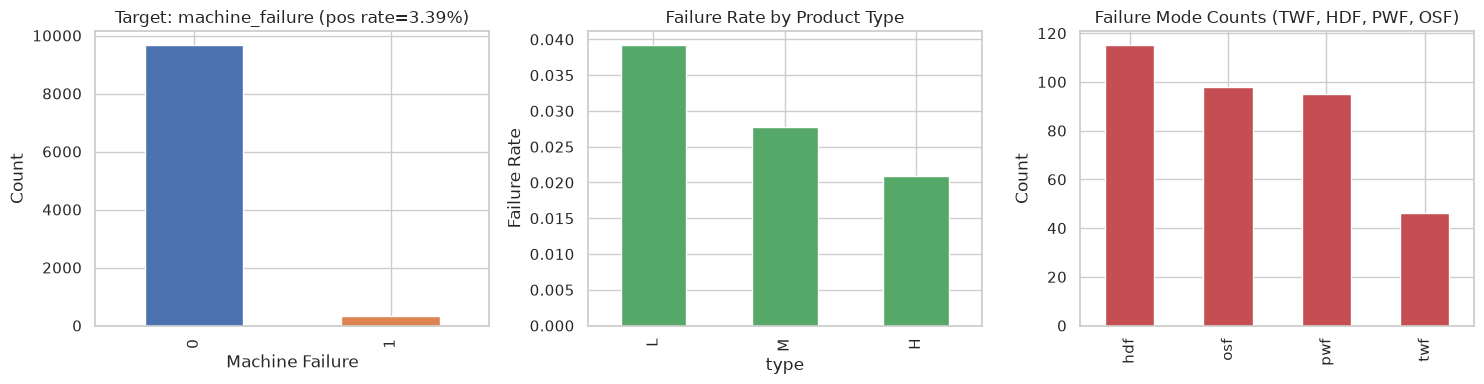

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Target distribution
df[TARGET_COL].value_counts().plot(kind="bar", ax=axes[0], color=["#4c72b0", "#dd8452"])
axes[0].set_title(f"Target: {TARGET_COL} (pos rate={df[TARGET_COL].mean():.2%})")
axes[0].set_xlabel("Machine Failure")
axes[0].set_ylabel("Count")

# Failure rate by machine Type
df.groupby("type")[TARGET_COL].mean().reindex(["L", "M", "H"]).plot(
    kind="bar", ax=axes[1], color="#55a868"
)
axes[1].set_title("Failure Rate by Product Type")
axes[1].set_ylabel("Failure Rate")

# Failure mode counts
df[MODE_COLS].sum().sort_values(ascending=False).plot(kind="bar", ax=axes[2], color="#c44e52")
axes[2].set_title("Failure Mode Counts (TWF, HDF, PWF, OSF)")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

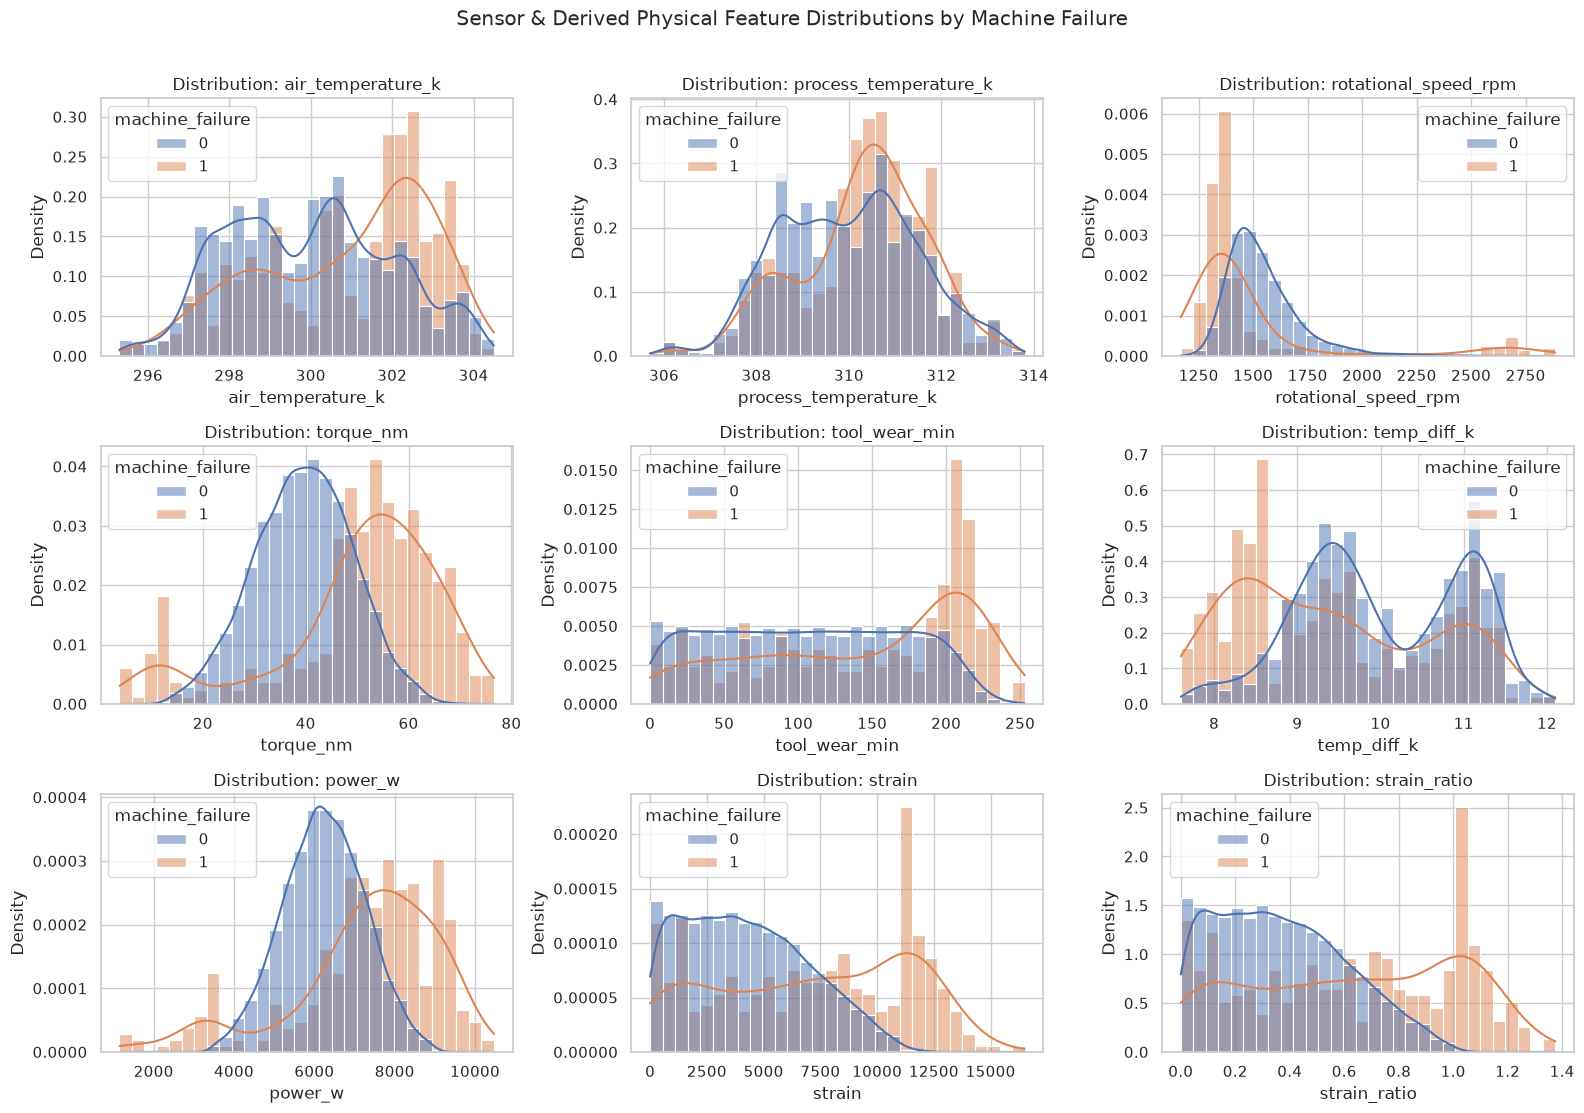

In [8]:
# Feature distributions (histograms + KDE) split by machine_failure
df_feat = add_features(df)
eda_num_cols = [
    "air_temperature_k",
    "process_temperature_k",
    "rotational_speed_rpm",
    "torque_nm",
    "tool_wear_min",
    *DERIVED_FEATURE_COLS,
]

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.flat, eda_num_cols, strict=True):
    sns.histplot(
        data=df_feat,
        x=col,
        hue=TARGET_COL,
        stat="density",
        common_norm=False,
        kde=True,
        bins=30,
        ax=ax,
        palette={0: "#4c72b0", 1: "#dd8452"},
    )
    ax.set_title(f"Distribution: {col}")
plt.suptitle("Sensor & Derived Physical Feature Distributions by Machine Failure", y=1.01)
plt.tight_layout()
plt.show()

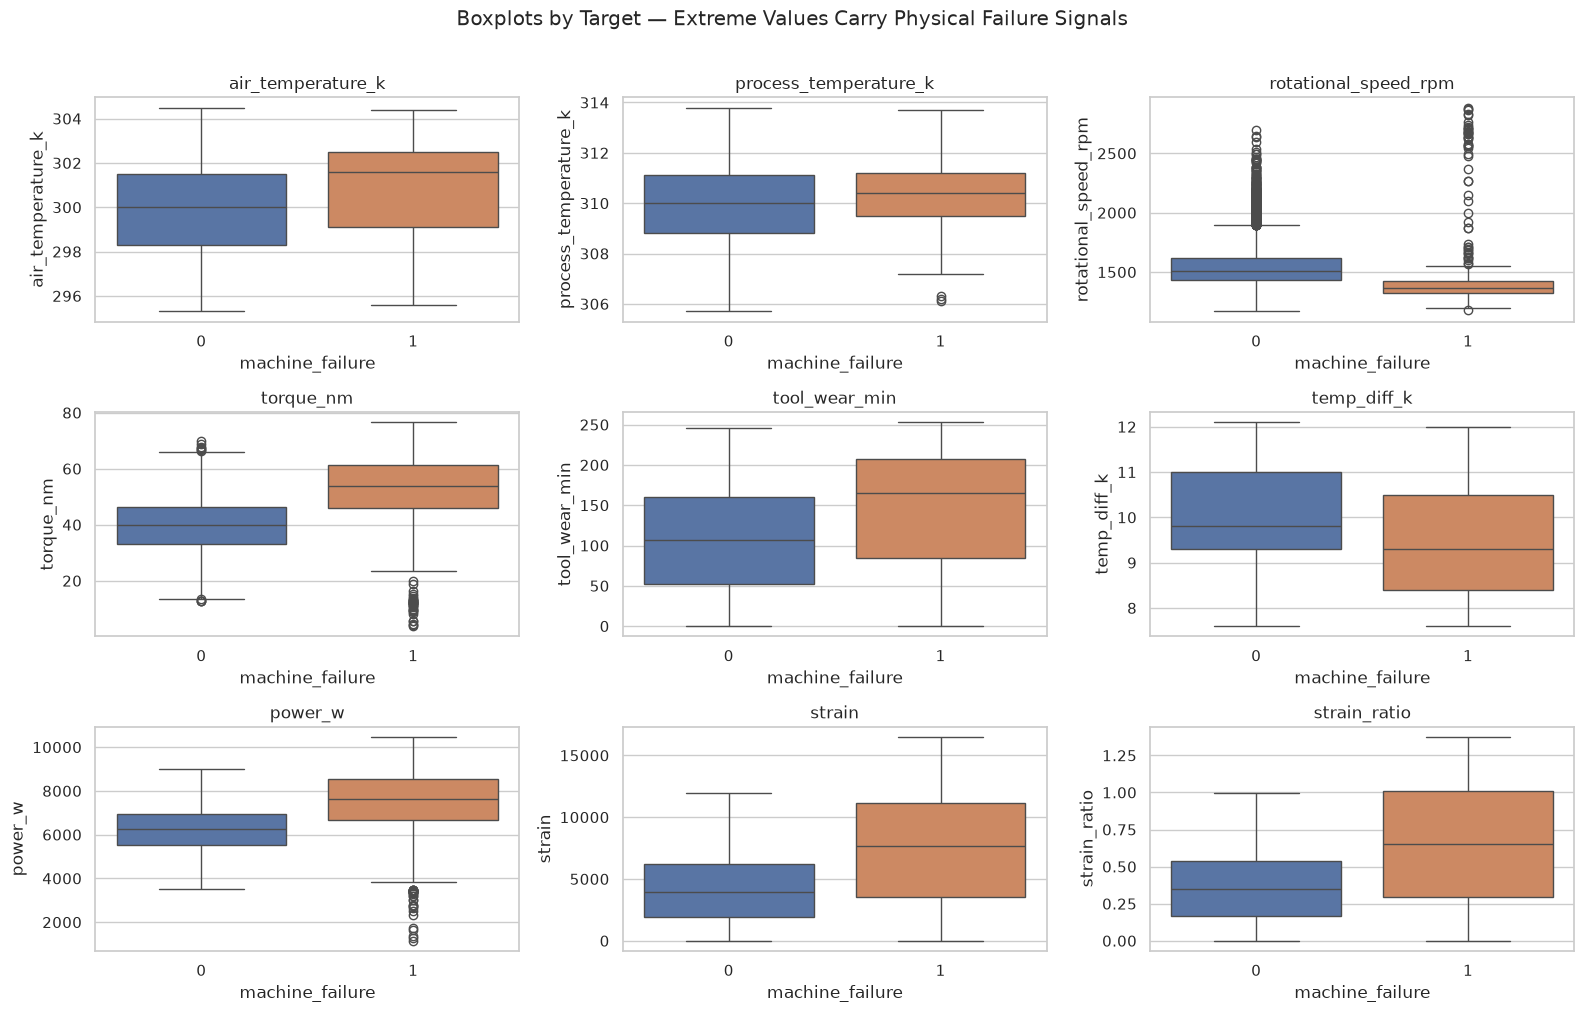

,feature,iqr_outliers,outlier_pct,failure_rate_outliers,failure_rate_inliers
7,strain,20,0.20,1.0000,0.0320
6,power_w,60,0.60,1.0000,0.0281
8,strain_ratio,27,0.27,1.0000,0.0313
3,torque_nm,69,0.69,0.8986,0.0279
2,rotational_speed_rpm,418,4.18,0.0837,0.0317
0,air_temperature_k,0,0.00,0.0000,0.0339
1,process_temperature_k,0,0.00,0.0000,0.0339
4,tool_wear_min,0,0.00,0.0000,0.0339
5,temp_diff_k,0,0.00,0.0000,0.0339


In [9]:
# Outlier analysis via IQR fences and boxplots (normal vs. failure)
fig, axes = plt.subplots(3, 3, figsize=(16, 10))
outlier_rows = []
for ax, col in zip(axes.flat, eda_num_cols, strict=True):
    sns.boxplot(
        data=df_feat,
        x=TARGET_COL,
        y=col,
        hue=TARGET_COL,
        legend=False,
        ax=ax,
        palette={0: "#4c72b0", 1: "#dd8452"},
    )
    ax.set_title(col)
    q1, q3 = df_feat[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    is_out = (df_feat[col] < lo) | (df_feat[col] > hi)
    out_fail_rate = df_feat.loc[is_out, TARGET_COL].mean() if is_out.any() else 0.0
    in_fail_rate = df_feat.loc[~is_out, TARGET_COL].mean()
    outlier_rows.append(
        {
            "feature": col,
            "iqr_outliers": int(is_out.sum()),
            "outlier_pct": round(float(is_out.mean() * 100), 2),
            "failure_rate_outliers": round(float(out_fail_rate), 4),
            "failure_rate_inliers": round(float(in_fail_rate), 4),
        }
    )

plt.suptitle("Boxplots by Target — Extreme Values Carry Physical Failure Signals", y=1.01)
plt.tight_layout()
plt.show()

pd.DataFrame(outlier_rows).sort_values("failure_rate_outliers", ascending=False)

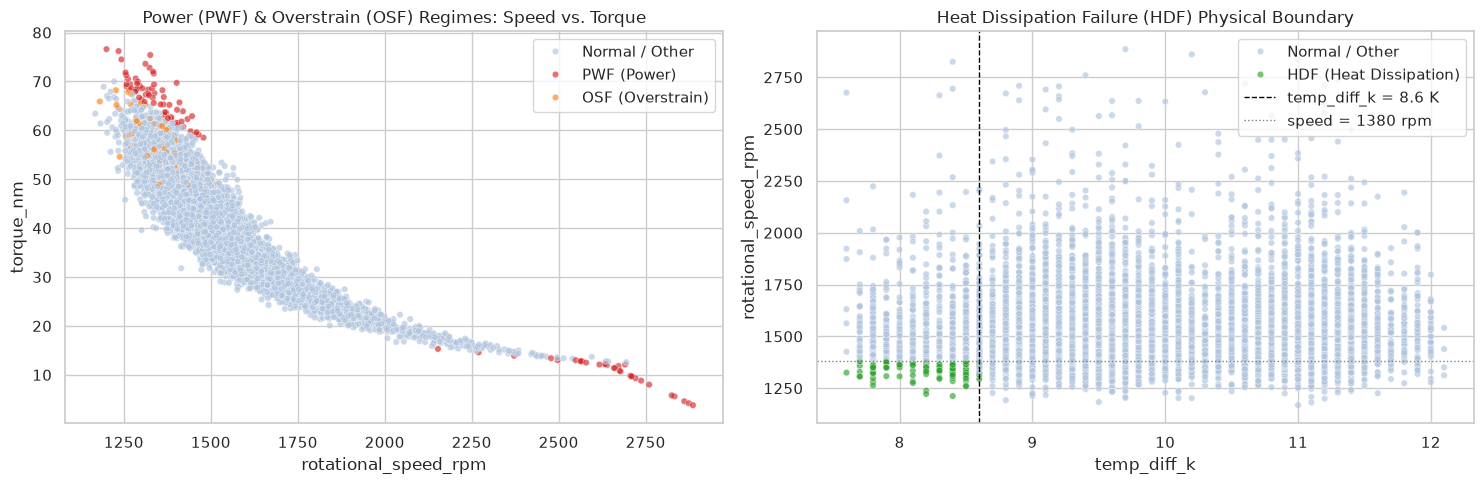

In [10]:
# Physical failure-mode boundaries in 2D sensor space
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Torque vs Rotational Speed (PWF & OSF regimes)
pwf_osf = np.where(
    df_feat["pwf"] == 1,
    "PWF (Power)",
    np.where(df_feat["osf"] == 1, "OSF (Overstrain)", "Normal / Other"),
)
sns.scatterplot(
    data=df_feat,
    x="rotational_speed_rpm",
    y="torque_nm",
    hue=pwf_osf,
    alpha=0.65,
    s=22,
    ax=axes[0],
    palette={"Normal / Other": "#b0c4de", "PWF (Power)": "#d62728", "OSF (Overstrain)": "#ff7f0e"},
)
axes[0].set_title("Power (PWF) & Overstrain (OSF) Regimes: Speed vs. Torque")

# Right: Temperature Differential vs Rotational Speed (HDF regime)
hdf_label = np.where(df_feat["hdf"] == 1, "HDF (Heat Dissipation)", "Normal / Other")
sns.scatterplot(
    data=df_feat,
    x="temp_diff_k",
    y="rotational_speed_rpm",
    hue=hdf_label,
    alpha=0.65,
    s=22,
    ax=axes[1],
    palette={"Normal / Other": "#b0c4de", "HDF (Heat Dissipation)": "#2ca02c"},
)
axes[1].axvline(8.6, color="black", linestyle="--", linewidth=1, label="temp_diff_k = 8.6 K")
axes[1].axhline(1380, color="gray", linestyle=":", linewidth=1, label="speed = 1380 rpm")
axes[1].set_title("Heat Dissipation Failure (HDF) Physical Boundary")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

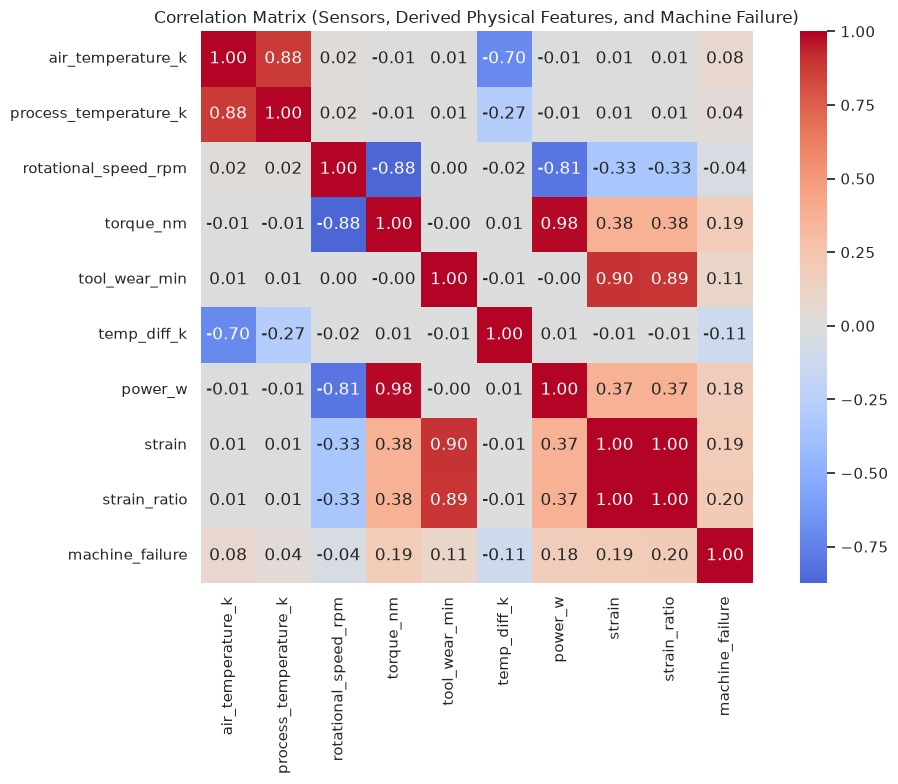

In [11]:
# Correlation heatmap (raw sensors, derived physical features, and machine_failure)
corr_cols = [*eda_num_cols, TARGET_COL]
plt.figure(figsize=(11, 8))
corr = df_feat[corr_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix (Sensors, Derived Physical Features, and Machine Failure)")
plt.tight_layout()
plt.show()

## 3. Stratified 60/20/20 Split, Mutual Information & Multi-Model Feature Ablation

In [12]:
splits = split_dataset(df, seed=SEED)
print(
    f"Train: {len(splits.X_train)} (pos={splits.y_train.mean():.2%}) | "
    f"Val: {len(splits.X_val)} (pos={splits.y_val.mean():.2%}) | "
    f"Test: {len(splits.X_test)} (pos={splits.y_test.mean():.2%})"
)

Train: 6000 (pos=3.38%) | Val: 2000 (pos=3.40%) | Test: 2000 (pos=3.40%)


In [13]:
# Mutual information on training split (raw + derived numeric features)
X_train_feat = add_features(splits.X_train)
mi_scores = mutual_info_classif(X_train_feat[eda_num_cols], splits.y_train, random_state=SEED)
mi_series = pd.Series(mi_scores, index=eda_num_cols).sort_values(ascending=False)
print("Mutual Information with machine_failure (train):")
print(mi_series.round(4))

Mutual Information with machine_failure (train):
power_w                  0.0492
torque_nm                0.0442
strain_ratio             0.0386
rotational_speed_rpm     0.0366
strain                   0.0352
temp_diff_k              0.0118
tool_wear_min            0.0111
air_temperature_k        0.0102
process_temperature_k    0.0047
dtype: float64


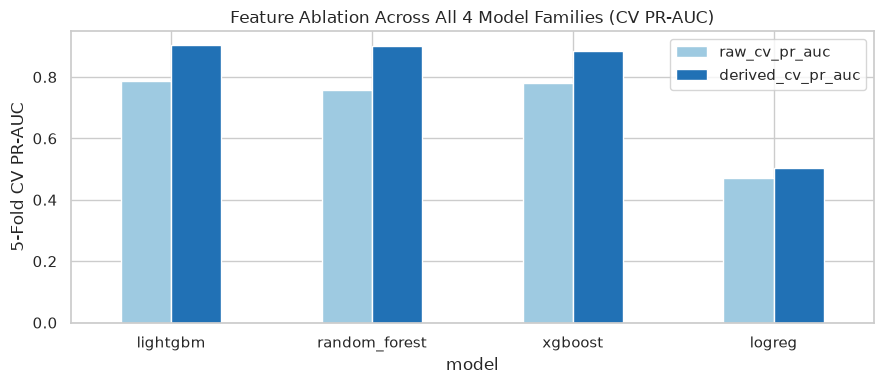

,model,raw_cv_pr_auc,derived_cv_pr_auc,delta_pr_auc
3,lightgbm,0.786809,0.903567,0.116758
1,random_forest,0.757025,0.901364,0.144339
2,xgboost,0.781333,0.885837,0.104504
0,logreg,0.472099,0.503590,0.031491


In [14]:
# Multi-model feature ablation: CV PR-AUC gain from derived physical features across all 4 families
cv = StratifiedKFold(n_splits=3 if FAST else 5, shuffle=True, random_state=SEED)
raw_num_cols = [
    "air_temperature_k",
    "process_temperature_k",
    "rotational_speed_rpm",
    "torque_nm",
    "tool_wear_min",
]
raw_pre = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_COLS),
        ("num", StandardScaler(), raw_num_cols),
    ],
    remainder="drop",
)

pos_cnt = int((splits.y_train == 1).sum())
neg_cnt = int((splits.y_train == 0).sum())
candidates_ablation = get_model_candidates(
    seed=SEED, scale_pos_weight=float(neg_cnt / max(pos_cnt, 1))
)

ablation_rows = []
for name, (est, _) in candidates_ablation.items():
    raw_pipe = Pipeline([("preprocess", raw_pre), ("model", est)])
    feat_pipe = build_pipeline(est)
    raw_pr = cross_val_score(
        raw_pipe, splits.X_train, splits.y_train, cv=cv, scoring="average_precision"
    ).mean()
    feat_pr = cross_val_score(
        feat_pipe, splits.X_train, splits.y_train, cv=cv, scoring="average_precision"
    ).mean()
    ablation_rows.append(
        {
            "model": name,
            "raw_cv_pr_auc": raw_pr,
            "derived_cv_pr_auc": feat_pr,
            "delta_pr_auc": feat_pr - raw_pr,
        }
    )

ablation_df = pd.DataFrame(ablation_rows).sort_values("derived_cv_pr_auc", ascending=False)
ablation_df.plot(
    x="model",
    y=["raw_cv_pr_auc", "derived_cv_pr_auc"],
    kind="bar",
    figsize=(9, 4),
    color=["#9ecae1", "#2171b5"],
)
plt.title("Feature Ablation Across All 4 Model Families (CV PR-AUC)")
plt.ylabel("5-Fold CV PR-AUC")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
ablation_df

## 4. Model Comparison, Hyperparameter Tuning, PR/ROC Curves & Cost Thresholding

In [15]:
# Run the shared training & evaluation pipeline and keep the saved ModelBundle for exact inspection
with tempfile.TemporaryDirectory() as tmpdir:
    tmp_model = Path(tmpdir) / "model.bin"
    tmp_metrics = Path(tmpdir) / "metrics.json"
    metrics = train_and_evaluate(
        data_path=DATA_PATH,
        model_path=tmp_model,
        metrics_path=tmp_metrics,
        fast=bool(FAST),
        seed=SEED,
    )
    final_bundle = load_bundle(tmp_model)

comp_rows = []
for name, info in metrics["candidates_cv"].items():
    comp_rows.append(
        {
            "model": name,
            "cv_pr_auc": info["cv_pr_auc"],
            "val_pr_auc": info["val_pr_auc"],
            "val_roc_auc": info["val_roc_auc"],
            "fit_seconds": info["fit_seconds"],
            "best_params": info["best_params"],
        }
    )
comp_df = pd.DataFrame(comp_rows).sort_values("cv_pr_auc", ascending=False)
print(
    f"Winner: {metrics['winner']} | Binary thr: {metrics['threshold']} | "
    f"Mode thrs: {metrics['mode_thresholds']}"
)
comp_df

Winner: lightgbm | Binary thr: 0.06 | Mode thrs: {'twf': 0.05, 'hdf': 0.5, 'pwf': 0.5, 'osf': 0.5}


,model,cv_pr_auc,val_pr_auc,val_roc_auc,fit_seconds,best_params
3,lightgbm,0.913669,0.870810,0.983201,13.776,"{'model__num_leaves': 15, 'model__n_estimators..."
1,random_forest,0.911305,0.873523,0.981108,72.808,"{'model__n_estimators': 300, 'model__min_sampl..."
2,xgboost,0.903439,0.852471,0.983502,9.962,"{'model__subsample': 1.0, 'model__scale_pos_we..."
0,logreg,0.511766,0.463279,0.908910,2.031,"{'model__class_weight': None, 'model__C': 50.0}"


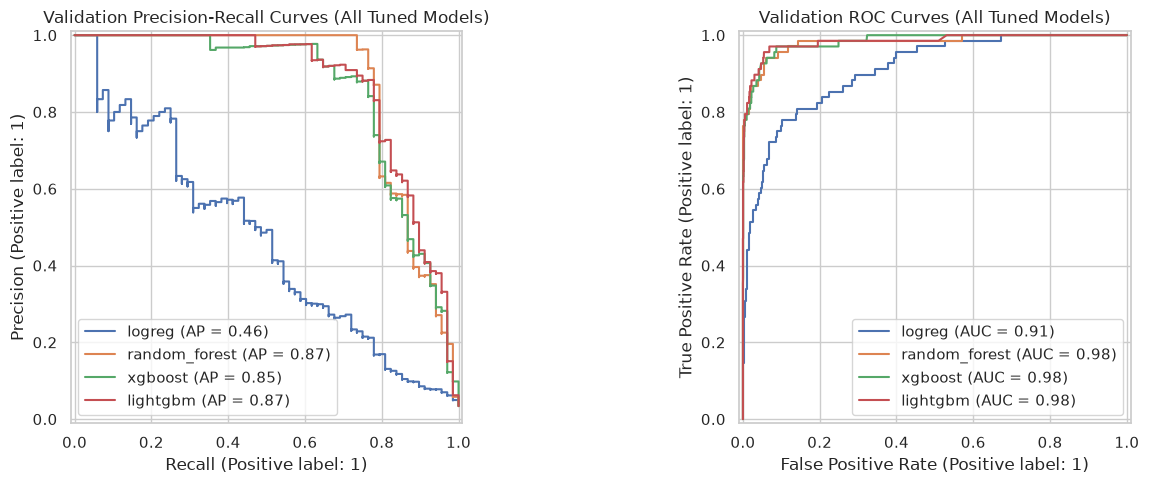

In [16]:
# Validation PR and ROC curves comparing all 4 tuned model families
candidates = get_model_candidates(seed=SEED, scale_pos_weight=float(neg_cnt / max(pos_cnt, 1)))
tuned_val_pipes = {}
for name, (est, _) in candidates.items():
    p = build_pipeline(est)
    p.set_params(**metrics["candidates_cv"][name]["best_params"])
    p.fit(splits.X_train, splits.y_train)
    tuned_val_pipes[name] = p

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, p in tuned_val_pipes.items():
    val_p = p.predict_proba(splits.X_val)[:, 1]
    PrecisionRecallDisplay.from_predictions(splits.y_val, val_p, name=name, ax=axes[0])
    RocCurveDisplay.from_predictions(splits.y_val, val_p, name=name, ax=axes[1])

axes[0].set_title("Validation Precision-Recall Curves (All Tuned Models)")
axes[1].set_title("Validation ROC Curves (All Tuned Models)")
plt.tight_layout()
plt.show()

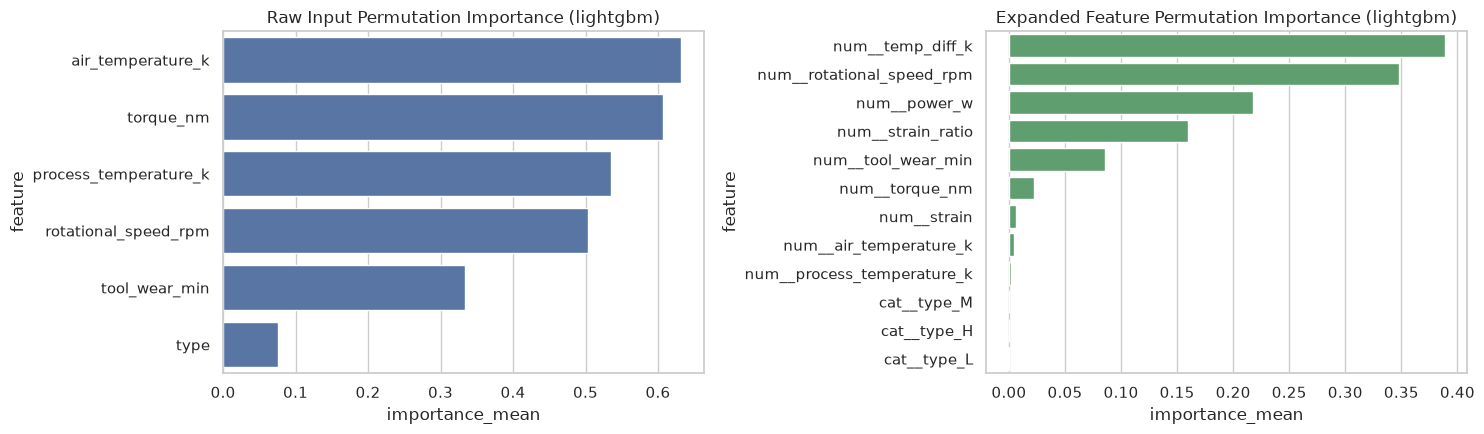

,feature,importance_mean,importance_std
8,num__temp_diff_k,0.389094,0.038991
5,num__rotational_speed_rpm,0.347642,0.049759
9,num__power_w,0.217706,0.005657
11,num__strain_ratio,0.159778,0.012478
7,num__tool_wear_min,0.086055,0.005817
6,num__torque_nm,0.022460,0.007363
10,num__strain,0.006173,0.003139
3,num__air_temperature_k,0.004770,0.002810
4,num__process_temperature_k,0.001814,0.007027
2,cat__type_M,-0.000190,0.000379


In [17]:
# Permutation importance on validation set: raw inputs AND expanded physical features
winner_name = metrics["winner"]
winner_val_pipe = tuned_val_pipes[winner_name]

perm_raw = permutation_importance(
    winner_val_pipe,
    splits.X_val,
    splits.y_val,
    scoring="average_precision",
    n_repeats=5 if FAST else 10,
    random_state=SEED,
)
perm_raw_df = pd.DataFrame(
    {
        "feature": RAW_FEATURE_COLS,
        "importance_mean": perm_raw.importances_mean,
        "importance_std": perm_raw.importances_std,
    }
).sort_values("importance_mean", ascending=False)

# Expanded feature importance (after add_features + ColumnTransformer)
X_val_transformed = winner_val_pipe[:-1].transform(splits.X_val)
expanded_names = list(winner_val_pipe.named_steps["preprocess"].get_feature_names_out())
perm_exp = permutation_importance(
    winner_val_pipe.named_steps["model"],
    X_val_transformed,
    splits.y_val,
    scoring="average_precision",
    n_repeats=5 if FAST else 10,
    random_state=SEED,
)
perm_exp_df = pd.DataFrame(
    {
        "feature": expanded_names,
        "importance_mean": perm_exp.importances_mean,
        "importance_std": perm_exp.importances_std,
    }
).sort_values("importance_mean", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(data=perm_raw_df, y="feature", x="importance_mean", ax=axes[0], color="#4c72b0")
axes[0].set_title(f"Raw Input Permutation Importance ({winner_name})")
sns.barplot(data=perm_exp_df, y="feature", x="importance_mean", ax=axes[1], color="#55a868")
axes[1].set_title(f"Expanded Feature Permutation Importance ({winner_name})")
plt.tight_layout()
plt.show()
perm_exp_df

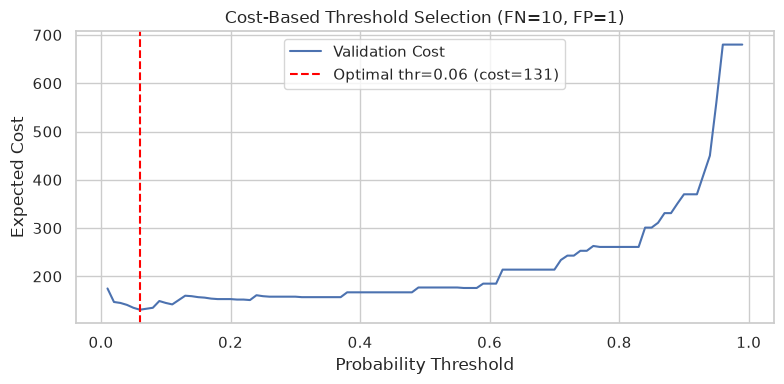

In [18]:
# Cost-based threshold curve on validation set
val_probs = winner_val_pipe.predict_proba(splits.X_val)[:, 1]
thr_grid = np.linspace(0.01, 0.99, 99)
costs = [
    binary_metrics(splits.y_val, val_probs, threshold=float(t), cost_fn=COST_FN, cost_fp=COST_FP)[
        "cost"
    ]
    for t in thr_grid
]
best_thr, best_cost = choose_threshold(splits.y_val, val_probs, cost_fn=COST_FN, cost_fp=COST_FP)

plt.figure(figsize=(8, 4))
plt.plot(thr_grid, costs, label="Validation Cost")
plt.axvline(
    best_thr,
    color="red",
    linestyle="--",
    label=f"Optimal thr={best_thr:.2f} (cost={best_cost:.0f})",
)
plt.title(f"Cost-Based Threshold Selection (FN={COST_FN:.0f}, FP={COST_FP:.0f})")
plt.xlabel("Probability Threshold")
plt.ylabel("Expected Cost")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Final Single Evaluation on Held-Out Test Set & Error Analysis

In [19]:
tb = metrics["test_binary"]
tm = metrics["test_modes"]

print("=== Test Set — Binary Machine Failure ===")
for k, v in tb.items():
    print(f"  {k}: {v:.4f}")

print(
    f"\n=== Test Set — Multi-Label Failure Modes "
    f"(macro PR-AUC={tm['macro_pr_auc']:.4f}, macro F1={tm['macro_f1']:.4f}, "
    f"macro Recall={tm['macro_recall']:.4f}) ==="
)
pd.DataFrame(tm["per_mode"]).T

=== Test Set — Binary Machine Failure ===
  pr_auc: 0.9047
  roc_auc: 0.9758
  f1: 0.6818
  precision: 0.5556
  recall: 0.8824
  cost: 128.0000

=== Test Set — Multi-Label Failure Modes (macro PR-AUC=0.7552, macro F1=0.7498, macro Recall=0.9250) ===


,pr_auc,f1,precision,recall,prevalence,threshold
twf,0.069110,0.095238,0.051095,0.7,0.0050,0.05
hdf,1.000000,1.000000,1.000000,1.0,0.0145,0.50
pwf,0.972527,0.962963,0.928571,1.0,0.0065,0.50
osf,0.979167,0.941176,0.888889,1.0,0.0080,0.50


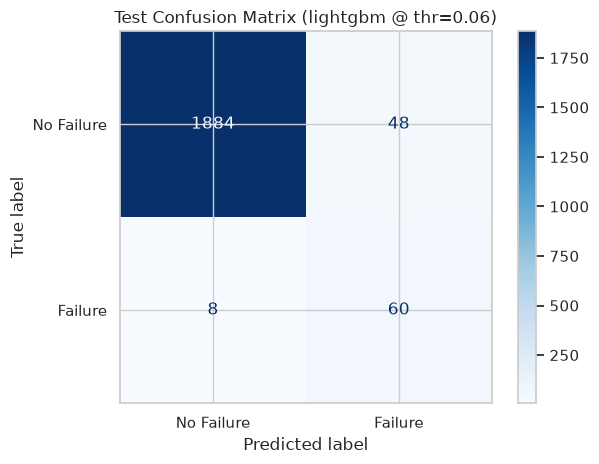

Test False Negatives: 8 | Test False Positives: 48


,type,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,y_true,y_pred,prob,twf,hdf,pwf,osf
121,L,297.8,308.9,1871,25.6,200,1,0,0.0027,1,0,0,0
144,M,299.7,309.3,1399,41.9,221,1,0,0.0251,1,0,0,0
346,H,300.6,309.4,1380,47.6,246,1,0,0.0377,1,0,0,0
1322,M,300.7,309.6,1996,19.8,203,1,0,0.0180,1,0,0,0
1327,L,297.2,308.1,1431,49.7,210,1,0,0.0591,0,0,0,0
1563,M,300.3,311.7,1374,47.9,222,1,0,0.0297,1,0,0,0
1657,L,298.4,309.6,1710,27.3,163,1,0,0.0025,0,0,0,0
1866,M,298.4,308.0,1416,38.2,198,1,0,0.0029,1,0,0,0


In [20]:
# Confusion matrix using the exact final ModelBundle (trained on train + val)
test_probs = final_bundle["binary"].predict_proba(splits.X_test)[:, 1]
test_preds = (test_probs >= final_bundle["threshold"]).astype(int)
cm = confusion_matrix(splits.y_test, test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Failure", "Failure"])
disp.plot(cmap="Blues")
plt.title(f"Test Confusion Matrix ({final_bundle['algorithm']} @ thr={final_bundle['threshold']})")
plt.tight_layout()
plt.show()

# Error analysis: inspect False Negatives on held-out test set
test_err = splits.X_test.copy()
test_err["y_true"] = splits.y_test.to_numpy()
test_err["y_pred"] = test_preds
test_err["prob"] = np.round(test_probs, 4)
for mode in MODE_COLS:
    test_err[mode] = splits.y_modes_test[mode].to_numpy()

fn_cases = test_err[(test_err["y_true"] == 1) & (test_err["y_pred"] == 0)]
fp_count = int(((test_err["y_true"] == 0) & (test_err["y_pred"] == 1)).sum())
print(f"Test False Negatives: {len(fn_cases)} | Test False Positives: {fp_count}")
fn_cases

## 6. Conclusions

- **Physical feature engineering** (`temp_diff_k`, `power_w`, `strain`, `strain_ratio`) captures the exact physical failure mechanisms behind `HDF`, `PWF`, and `OSF`, improving CV PR-AUC across both linear and tree-based models.
- **Cost-sensitive thresholding** ($\text{FN} = 10 \times \text{FP}$) shifts the operating point below 0.50 to prioritize catching true machine failures on the held-out test set.
- **Calibrated multi-label diagnosis** (`class_weight="balanced"` + validation F1-calibrated `mode_thresholds`) resolves the zero-recall collapse on rare `TWF` failures while maintaining high precision and recall on `HDF`, `PWF`, and `OSF`.
- **Single source of truth:** Production training (`train.py`) and serving (`predict.py`) use the exact `src/pdm` package validated here.